### Импорт библиотек, загрузка изображения


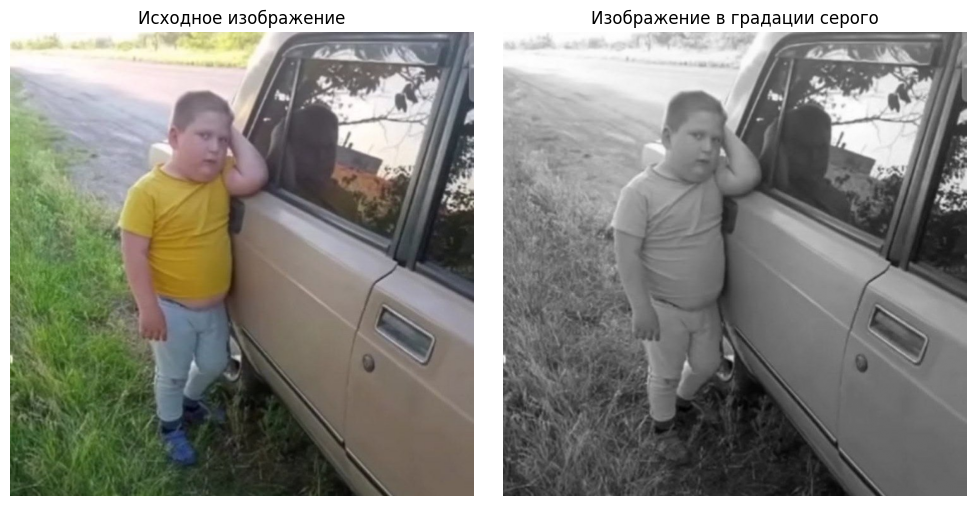

In [23]:
import cv2
import matplotlib.pyplot as plt
import numpy as np

img = cv2.imread('image.jpg')
img_gray = cv2.imread('image.jpg', cv2.IMREAD_GRAYSCALE)

if img is None or img_gray is None:
    raise FileNotFoundError("Файл image.jpg не найден.")

def show_image(images, titles, figsize=(15, 5)):

    if not isinstance(images, (list, tuple)):
        images = [images]
    if not isinstance(titles, (list, tuple)):
        titles = [titles]

    fig, axes = plt.subplots(1, len(images), figsize=figsize)

    if len(images) == 1:
        axes = [axes]

    for ax, image, title in zip(axes, images, titles):
        if image.ndim == 2:
            ax.imshow(image, cmap='gray')
        else:
            ax.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB))

        ax.set_title(title)
        ax.axis('off')

    plt.tight_layout()
    plt.show()

show_image([img, img_gray], ['Исходное изображение', 'Изображение в градации серого'], figsize=(10, 5))


### Задание 1. Применить усредняющий фильтр (размер окон 3х3 и 9х9)


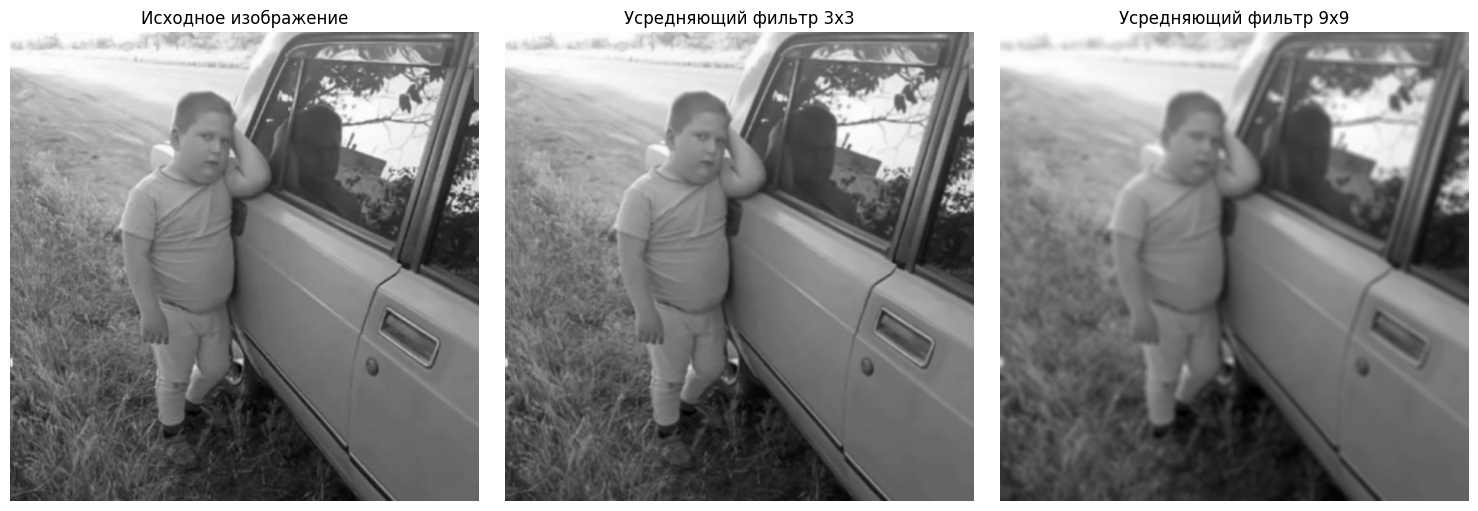

In [24]:
mean_3 = cv2.blur(img_gray, (3, 3))
mean_9 = cv2.blur(img_gray, (9, 9))

show_image([img_gray, mean_3, mean_9],['Исходное изображение','Усредняющий фильтр 3x3','Усредняющий фильтр 9x9'],figsize=(15, 5))

### Задание 2. Сравнить работу медианного и гауссова фильтров на изображении с шумом

MSE медианного фильтра: 12.09
MSE гауссова фильтра:   95.64


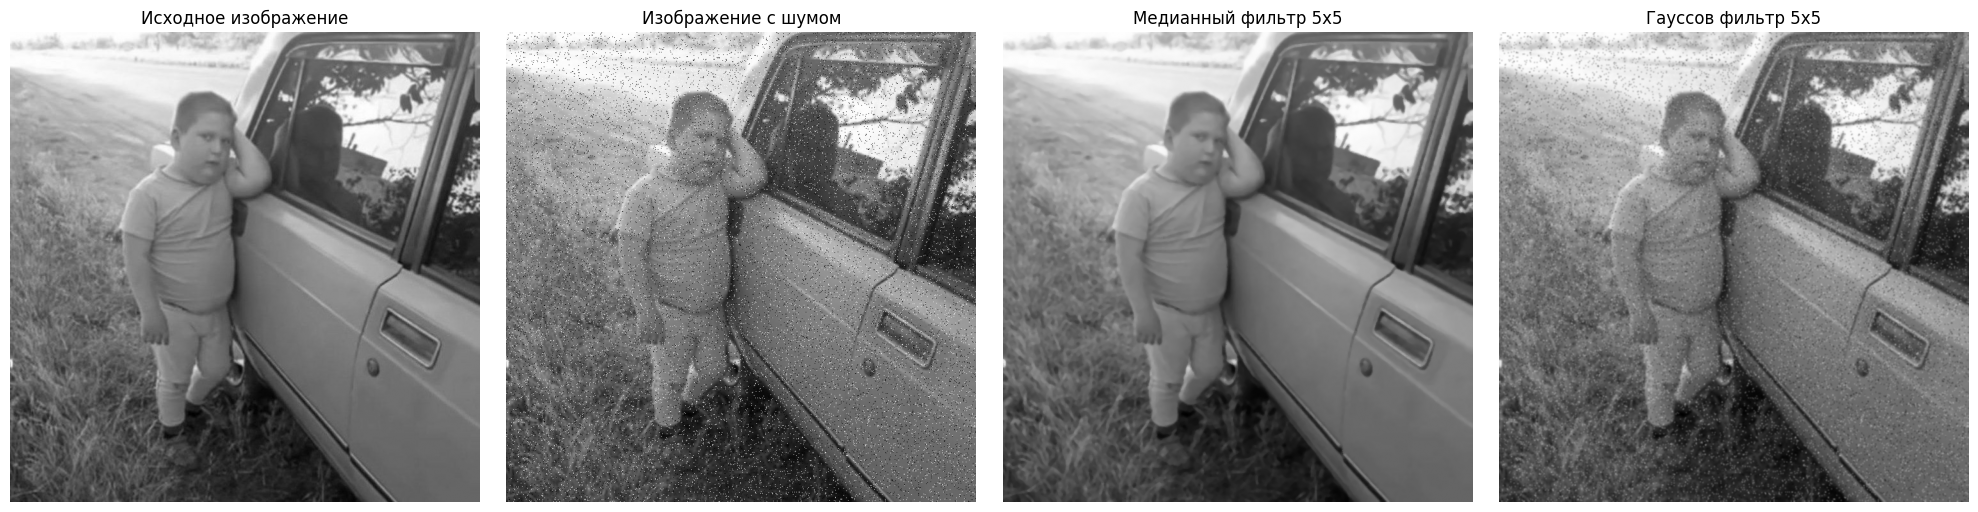

In [25]:
noisy = img_gray.copy()

rng = np.random.default_rng(42)
noise_mask = rng.random(img_gray.shape)

noisy[noise_mask < 0.025] = 0
noisy[noise_mask > 0.975] = 255

median_filtered = cv2.medianBlur(noisy, 5)
gaussian_filtered = cv2.GaussianBlur(noisy, (5, 5), 1.0)

mse_median = np.mean((img_gray.astype(np.float32) - median_filtered.astype(np.float32)) ** 2)
mse_gaussian = np.mean((img_gray.astype(np.float32) - gaussian_filtered.astype(np.float32)) ** 2)

print(f'MSE медианного фильтра: {mse_median:.2f}')
print(f'MSE гауссова фильтра:   {mse_gaussian:.2f}')

show_image([img_gray, noisy, median_filtered, gaussian_filtered],['Исходное изображение','Изображение с шумом','Медианный фильтр 5x5','Гауссов фильтр 5x5'],figsize=(20, 5))

### Задание 3. Построить градиентное изображение по оператору Собеля


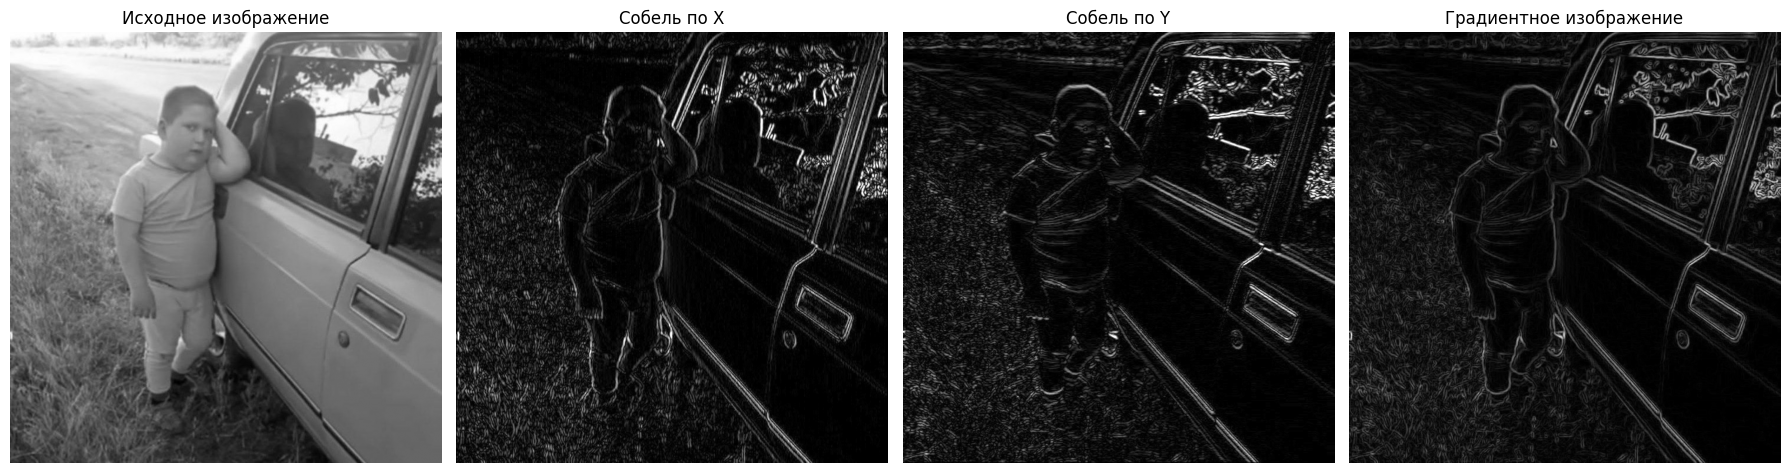

In [26]:
sobel_x = cv2.Sobel(img_gray, cv2.CV_64F, 1, 0, ksize=3)
sobel_y = cv2.Sobel(img_gray, cv2.CV_64F, 0, 1, ksize=3)

sobel_x_show = cv2.convertScaleAbs(sobel_x)
sobel_y_show = cv2.convertScaleAbs(sobel_y)

gradient = np.sqrt(sobel_x ** 2 + sobel_y ** 2)
gradient = cv2.normalize(
    gradient, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

show_image([img_gray, sobel_x_show, sobel_y_show, gradient],['Исходное изображение','Собель по X','Собель по Y','Градиентное изображение'],figsize=(18, 5))

### Задание 4. Применить гауссов фильтр с большим σ для сильного размытия

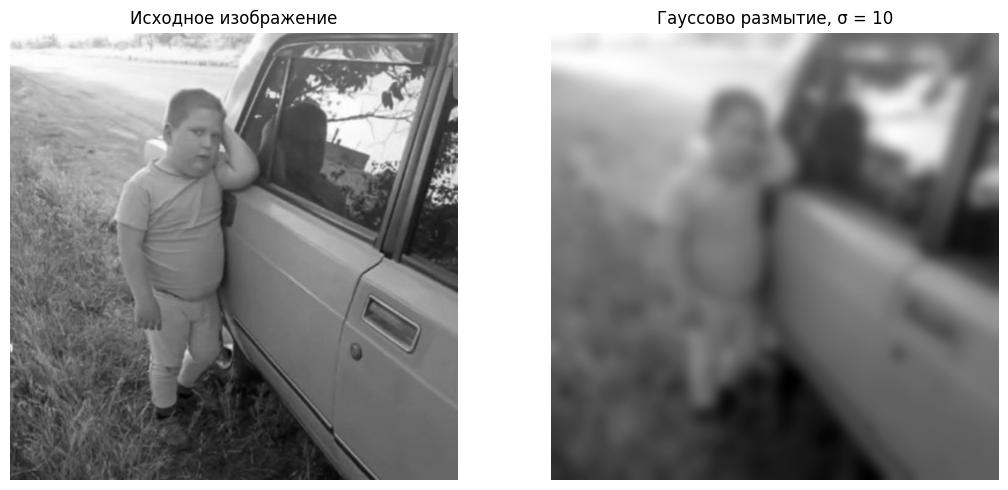

In [27]:
sigma = 10

strong_gaussian = cv2.GaussianBlur(img_gray, (0, 0), sigmaX=sigma, sigmaY=sigma)

show_image([img_gray, strong_gaussian],['Исходное изображение', f'Гауссово размытие, σ = {sigma}'],figsize=(11, 5))

### Задание 5. Реализовать гауссов НЧ-фильтр в частотной области


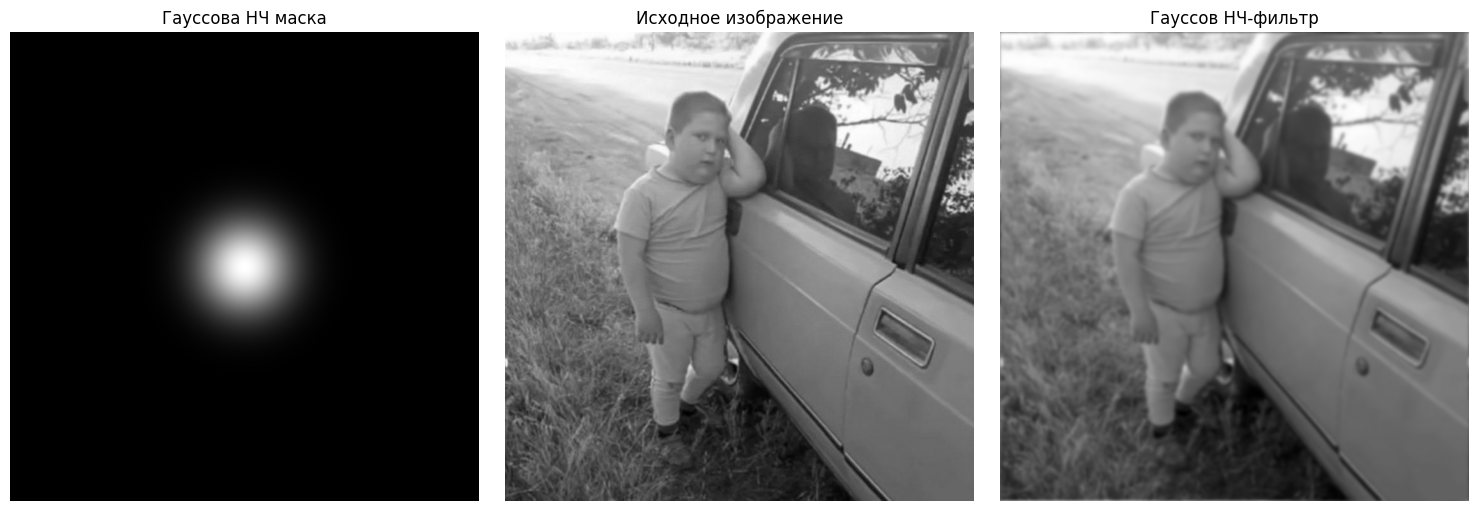

In [28]:
f = np.fft.fft2(img_gray)
f_shift = np.fft.fftshift(f)

rows, cols = img_gray.shape
crow, ccol = rows // 2, cols // 2

y, x = np.ogrid[:rows, :cols]

distance_squared = (y - crow) ** 2 + (x - ccol) ** 2

D0 = 50

gaussian_lpf = np.exp(-distance_squared / (2 * D0 ** 2))

filtered_shift = f_shift * gaussian_lpf

filtered = np.fft.ifft2(np.fft.ifftshift(filtered_shift))
filtered = np.abs(filtered)

filtered = cv2.normalize(
    filtered, None, 0, 255, cv2.NORM_MINMAX
).astype(np.uint8)

show_image([gaussian_lpf, img_gray, filtered],['Гауссова НЧ маска','Исходное изображение','Гауссов НЧ-фильтр'],figsize=(15, 5))